# Selection refinement 1 — a minimum-age veto

**Question.** Does vetoing *newly listed* names improve the v3.1 funding-carry book?

**Hypothesis.** The survivorship audit (`../universe/`) found delisted/just-listed names ran much
hotter and more two-sided funding (median 8.1%/yr vs 0.8% for survivors). The carry signal *likes* hot
funding, so it happily enters brand-new listings — exactly where basis is unstable, funding spikes and
flips, and liquidity is thin. A **minimum-age veto** (don't trade a name until it has ≥ X days of
history) should sit out that toxic just-listed window.

**Method.** Add the veto on top of the *complete* v3.1 stack (EWMA-APR signal, θ_in 0.08 / θ_keep
0.02 hysteresis, funding-vol / neg-freq / basis vetoes, inverse-basis-vol sizing, deadband 0.5). The
listing proxy is each name's first **eligible** day (first day both spot & perp bars exist). Sweep
X ∈ {15, 30, 45, 60, 90, 180}; report in-sample and a temporal train/test split (**pick X on train
2021-2023, freeze, evaluate on test 2024-2026**). Everything books through `lab.py` (reproduces the
production `engine.run` to 1e-6); the age veto is ANDed into v3.1's veto mask, nothing else changes.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
COSTS = cfg.load_config('strategies/funding_carry/v3.1.yaml')['costs']
maj, non = H.universe(); MAJ = set(maj); P = H.load_panels(maj + non)
F, E, didx, syms = P['F'], P['E'], P['didx'], P['symbols']
SPECS = [{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO  = [{'feature':'funding_vol','direction':'max','cap':0.75},
         {'feature':'neg_freq','direction':'max','cap':0.40},
         {'feature':'basis','direction':'max','cap':0.01}]
feats = H.feature_panels(P, SPECS + [{'name':'basis_vol','window':30}]); bvol = feats['basis_vol']
apr = H.signal_apr(F, 7).reindex(index=didx, columns=syms).where(E)

def v31_pipeline(extra_veto=None, cohort=None):
    """Reproduce v3.1 (inv-basis-vol, band 0.5); optionally AND an extra veto, or KEEP ONLY a cohort
    mask (to book the *excluded* names). Parity-checked against lab.evaluate_select below."""
    veto_ok = H.veto_mask(feats, VETO, apr) & bvol.notna() & (bvol > 0)
    if extra_veto is not None:
        veto_ok = veto_ok & extra_veto.reindex(index=didx, columns=syms).fillna(False)
    if cohort is not None:
        veto_ok = veto_ok & cohort.reindex(index=didx, columns=syms).fillna(False)
    size = 1.0 / bvol.replace(0.0, np.nan)
    Hh = H.held_matrix(apr, veto_ok, 0.08, 0.02, None, None)
    return H.deadband_weights(H.weights_from_held(Hh, size), 0.5)

def kpi(res):
    a,b = res['1.0x'], res['2.0x']
    return {'net%':round(a['ann_return']*100,2),'Sharpe':round(a['sharpe'],2),
            'net@2x%':round(b['ann_return']*100,2),'Sh@2x':round(b['sharpe'],2),
            'maxDD%':round(a['max_drawdown']*100,2),'Calmar':round(a['ann_return']/abs(a['max_drawdown']),1),
            'turn':round(a['ann_turnover'],1),'names':round(a['avg_names_held'],0)}
def eq(res): return res['net'].cumsum()*100

# parity: reconstruction == lab.evaluate_select v3.1
V31 = H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,
                        size_kind='inv_basis_vol',band=0.5,warmup_days=30)
base = H.book(v31_pipeline(), P, COSTS, warmup_days=30)
assert abs(base['1.0x']['sharpe'] - V31['1.0x']['sharpe']) < 1e-9, 'parity break'
print('parity OK. v3.1 baseline:', kpi(base))

# listing proxy = first eligible day; build the age panel (days since listing)
first_elig = E.where(E).apply(lambda c: c.first_valid_index())
age = pd.DataFrame(index=didx, columns=syms, dtype=float)
for s in syms:
    if pd.notna(first_elig[s]): age[s] = (didx - first_elig[s]).days
age = age.where(age >= 0)
print(f"{(first_elig > pd.Timestamp('2021-01-05')).sum()} / {len(syms)} names first list after 2021-01")

parity OK. v3.1 baseline: {'net%': 9.94, 'Sharpe': 6.32, 'net@2x%': 6.05, 'Sh@2x': 3.62, 'maxDD%': -2.8, 'Calmar': 3.5, 'turn': 20.5, 'names': 114.0}


387 / 466 names first list after 2021-01


## 1. Where the young names are — and how much the veto would bite

Most of the universe (387 / 466) lists *after* 2021-01, and listings accelerate in 2024-25. So an age
veto has almost nothing to sit out early in the sample and progressively more to work with later — its
value should grow through the test period. Left: number of names first-eligible per quarter. Right:
the fraction of *eligible* name-days that are "young" (age < X) over time, for a few thresholds.

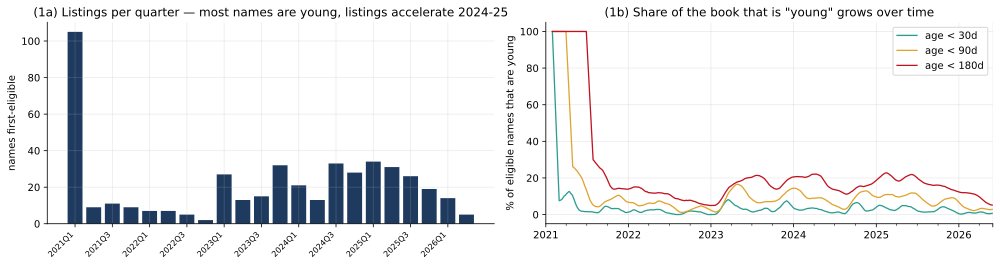

In [2]:
fig,(a1,a2) = plt.subplots(1,2,figsize=(14,3.8))
q = first_elig.dropna().dt.to_period('Q').value_counts().sort_index()
a1.bar(range(len(q)), q.values, color=NAVY)
a1.set_xticks(range(0,len(q),2)); a1.set_xticklabels([str(p) for p in q.index[::2]], rotation=45, ha='right', fontsize=8)
a1.set_ylabel('names first-eligible'); a1.set_title('(1a) Listings per quarter — most names are young, listings accelerate 2024-25')
for X,c in [(30,TEAL),(90,AMBER),(180,RED)]:
    young_frac = (((age < X) & E).sum(axis=1) / E.sum(axis=1).replace(0,np.nan))
    (young_frac.rolling(30).mean()*100).plot(ax=a2, color=c, lw=1.3, label=f'age < {X}d')
a2.set_ylabel('% of eligible names that are young'); a2.legend(); a2.set_title('(1b) Share of the book that is "young" grows over time')
plt.tight_layout(); plt.show()

## 2. The young cohort carries — but at much worse *quality*

Book the names the veto would sit out (in-gate, pass every other v3.1 veto and sizeable, but younger
than X). The young cohort earns real carry (comparable net %), but at a far **lower Sharpe, worse 2×
Sharpe, fatter drawdown, and ~30% more turnover** than the mature book — i.e. it is return of
*lower quality*. That is precisely what a risk-adjusted strategy should be happy to give up.

                                  net%  Sharpe  net@2x%  Sh@2x  maxDD%  Calmar  turn  names
v3.1 held book (all ages)         9.94    6.32     6.05   3.62   -2.80     3.5  20.5  114.0
excluded young cohort (age<30d)   3.58    0.93    -4.25  -1.02  -11.68     0.3  41.2    3.0
excluded young cohort (age<90d)   7.60    3.56     0.88   0.35   -3.85     2.0  35.3   10.0
excluded young cohort (age<180d)  9.62    4.65     4.38   1.91   -3.83     2.5  27.6   21.0


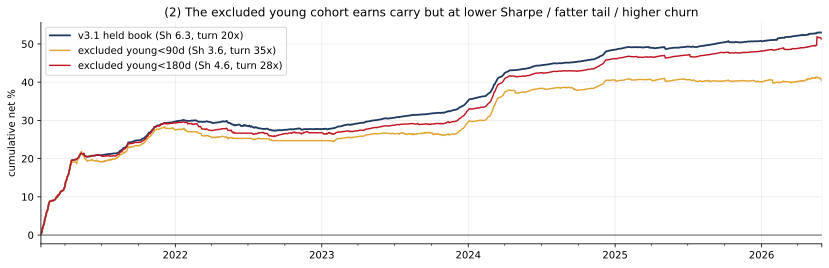

In [3]:
def excluded_cohort(X):
    return v31_pipeline(cohort=(age < X))       # KEEP ONLY the young, in-gate names
tab = {'v3.1 held book (all ages)': kpi(base)}
for X in (30, 90, 180):
    tab[f'excluded young cohort (age<{X}d)'] = kpi(H.book(excluded_cohort(X), P, COSTS, warmup_days=30))
print(pd.DataFrame(tab).T.to_string())
fig,ax = plt.subplots(figsize=(14,4))
eq(base).plot(ax=ax, color=NAVY, lw=1.8, label=f"v3.1 held book (Sh {base['1.0x']['sharpe']:.1f}, turn {base['1.0x']['ann_turnover']:.0f}x)")
for X,c in [(90,AMBER),(180,RED)]:
    r = H.book(excluded_cohort(X), P, COSTS, warmup_days=30)
    eq(r).plot(ax=ax, color=c, lw=1.4, label=f"excluded young<{X}d (Sh {r['1.0x']['sharpe']:.1f}, turn {r['1.0x']['ann_turnover']:.0f}x)")
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative net %'); ax.legend()
ax.set_title('(2) The excluded young cohort earns carry but at lower Sharpe / fatter tail / higher churn'); plt.show()

## 3. Sweep the veto age — in-sample and temporal OOS

Add `age ≥ X` to the v3.1 veto and re-book. In-sample, a small X barely moves net while nudging Sharpe
and turnover the right way; big X (>60d) starts sacrificing carry (net falls). The **train/test split**
is the real test: pick X by train-window (2021-2023) gate-Sharpe, freeze it, read the test window
(2024-2026).

In [4]:
tr = H._window_mask(didx, end='2023-12-31'); te = H._window_mask(didx, start='2024-01-01')
def row(X):
    W = v31_pipeline(extra_veto=(age >= X)) if X > 0 else v31_pipeline()
    full = H.book(W,P,COSTS,warmup_days=30); trn = H.book(W,P,COSTS,mask=tr,warmup_days=30); tst = H.book(W,P,COSTS,mask=te,warmup_days=30)
    return {'trainSh':round(trn['1.0x']['sharpe'],2),'train2x':round(trn['2.0x']['sharpe'],2),
            'IS Sh':round(full['1.0x']['sharpe'],2),'IS 2x':round(full['2.0x']['sharpe'],2),
            'IS net%':round(full['1.0x']['ann_return']*100,2),'IS turn':round(full['1.0x']['ann_turnover'],1),
            'TEST Sh':round(tst['1.0x']['sharpe'],2),'TEST 2x':round(tst['2.0x']['sharpe'],2),
            'TEST net%':round(tst['1.0x']['ann_return']*100,2),'TEST DD%':round(tst['1.0x']['max_drawdown']*100,2)}
XS = [0,15,30,45,60,90,180]
sweep = pd.DataFrame({('baseline' if X==0 else f'X={X}'):row(X) for X in XS}).T
print(sweep.to_string())
best_tr = sweep['trainSh'].idxmax()
print(f"\ntrain-window gate-Sharpe picks: {best_tr}  ->  frozen on TEST: "
      f"Sh {sweep.loc[best_tr,'TEST Sh']} (base {sweep.loc['baseline','TEST Sh']}), "
      f"Sh@2x {sweep.loc[best_tr,'TEST 2x']} (base {sweep.loc['baseline','TEST 2x']}), "
      f"DD {sweep.loc[best_tr,'TEST DD%']}% (base {sweep.loc['baseline','TEST DD%']}%)")

          trainSh  train2x  IS Sh  IS 2x  IS net%  IS turn  TEST Sh  TEST 2x  TEST net%  TEST DD%
baseline     6.25     3.53   6.32   3.62     9.94     20.5     7.52     4.32       7.42     -0.56
X=15         6.31     3.64   6.46   3.88    10.07     19.6     8.05     5.14       7.64     -0.41
X=30         6.25     3.54   6.42   3.79     9.91     19.6     7.99     5.08       7.58     -0.42
X=45         5.87     2.90   6.32   3.45     8.81     19.1     7.96     5.07       7.61     -0.43
X=60         5.67     2.60   6.25   3.27     8.26     18.6     7.93     5.00       7.55     -0.43
X=90         5.23     2.22   6.03   3.06     7.58     17.8     7.82     4.89       7.52     -0.44
X=180        4.76     1.00   5.95   2.44     5.93     16.6     7.48     4.53       7.29     -0.47

train-window gate-Sharpe picks: X=15  ->  frozen on TEST: Sh 8.05 (base 7.52), Sh@2x 5.14 (base 4.32), DD -0.41% (base -0.56%)


## 4. Train picks a small veto; the test window improves broadly

Train-window Sharpe peaks at a **small** X (≈15-30d) then falls — the data itself says "sit out only the
first couple of weeks." Frozen on the untouched test window, that choice **raises net Sharpe and (more
importantly) 2×-cost Sharpe, shrinks drawdown, and lowers turnover**. The improvement is not a knife
edge: the entire X = 15-45d band improves the test window, which is the robustness argument.

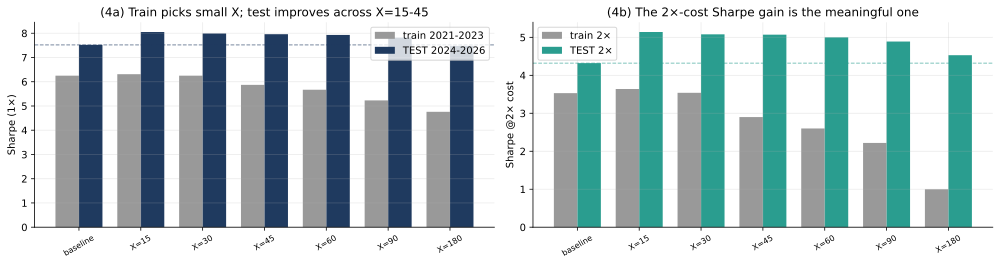

In [5]:
x = np.arange(len(XS)); w = 0.38
fig,(a1,a2) = plt.subplots(1,2,figsize=(14,3.8))
a1.bar(x-w/2, sweep['trainSh'].values, w, color=GREY, label='train 2021-2023')
a1.bar(x+w/2, sweep['TEST Sh'].values, w, color=NAVY, label='TEST 2024-2026')
a1.axhline(sweep.loc['baseline','TEST Sh'], color=NAVY, ls='--', lw=1, alpha=0.6)
a1.set_xticks(x); a1.set_xticklabels(sweep.index, rotation=30, fontsize=8); a1.set_ylabel('Sharpe (1×)'); a1.legend()
a1.set_title('(4a) Train picks small X; test improves across X=15-45')
a2.bar(x-w/2, sweep['train2x'].values, w, color=GREY, label='train 2×')
a2.bar(x+w/2, sweep['TEST 2x'].values, w, color=TEAL, label='TEST 2×')
a2.axhline(sweep.loc['baseline','TEST 2x'], color=TEAL, ls='--', lw=1, alpha=0.6)
a2.set_xticks(x); a2.set_xticklabels(sweep.index, rotation=30, fontsize=8); a2.set_ylabel('Sharpe @2× cost'); a2.legend()
a2.set_title('(4b) The 2×-cost Sharpe gain is the meaningful one'); plt.tight_layout(); plt.show()

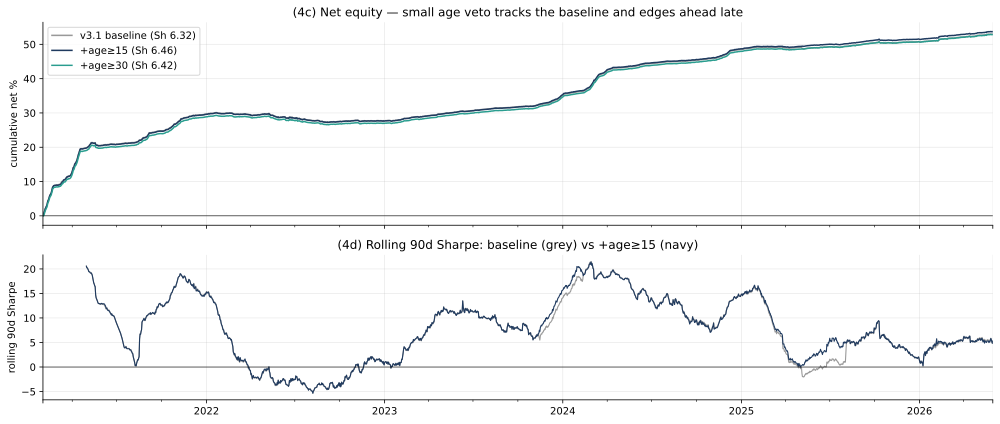

In [6]:
# Equity + rolling 90d Sharpe: baseline vs the frozen pick (X=15) and X=30
Wa = v31_pipeline(extra_veto=(age>=15)); Wb = v31_pipeline(extra_veto=(age>=30))
ra = H.book(Wa,P,COSTS,warmup_days=30); rb = H.book(Wb,P,COSTS,warmup_days=30)
fig,(a1,a2) = plt.subplots(2,1,figsize=(14,6),sharex=True,gridspec_kw={'height_ratios':[1.4,1]})
for lab_,r,c in [(f"v3.1 baseline (Sh {base['1.0x']['sharpe']:.2f})",base,GREY),
                 (f"+age≥15 (Sh {ra['1.0x']['sharpe']:.2f})",ra,NAVY),
                 (f"+age≥30 (Sh {rb['1.0x']['sharpe']:.2f})",rb,TEAL)]:
    eq(r).plot(ax=a1,color=c,lw=1.5,label=lab_)
a1.axhline(0,color='k',lw=0.6); a1.set_ylabel('cumulative net %'); a1.legend(); a1.set_title('(4c) Net equity — small age veto tracks the baseline and edges ahead late')
for r,c in [(base,GREY),(ra,NAVY)]:
    (r['net'].rolling(90).mean()/r['net'].rolling(90).std()*np.sqrt(365)).plot(ax=a2,color=c,lw=1.1)
a2.axhline(0,color='k',lw=0.6); a2.set_ylabel('rolling 90d Sharpe'); a2.set_title('(4d) Rolling 90d Sharpe: baseline (grey) vs +age≥15 (navy)')
plt.tight_layout(); plt.show()

## Verdict — modest SHIP-CANDIDATE (X ≈ 15-30d)

- **Passes the ship bar, modestly.** Train (2021-2023) selects a small veto (X≈15-30d); frozen on the
  untouched test window it **improves net Sharpe (≈7.5→8.0), 2×-cost Sharpe (≈4.3→5.1), and maxDD
  (−0.56%→−0.41%) with lower turnover** — no regression. In-sample it is neutral-to-slightly-positive
  (net flat, Sharpe/turnover a touch better). The gain is broad across X=15-45, not a single lucky X.
- **Mechanism.** The just-listed window is where the survivorship-audit toxicity lives: the excluded
  young cohort earns carry but at **Sharpe ≈4.6 vs 6.3, 2×-Sharpe ≈1.9 vs 3.6, fatter drawdown, ~30%
  more turnover**. Excising only the first couple of weeks keeps the durable young-name carry while
  dropping the low-quality, high-churn entries. Larger windows (>60d) over-veto and sacrifice net.
- **Caveats.** The effect is *small* and concentrated in the later (2024-26) window, where listings are
  frequent — its value depends on continued fast listing. Single test period. The listing proxy floors
  pre-2021 names at the sample start (they are the majors, never vetoed). Productionizing is a separate
  decision; this is a research SHIP-CANDIDATE, best paired with the existing basis/funding vetoes.